# Foundations of Data Science
## Tutorial 3 — Eigenvectors, Projections, and the Greedy SVD

**Prepared by Dr. João A. Gonçalves**

This is the worked solution notebook for Exercise Sheet 3. It mirrors the student notebook but includes derivations, complete code, numerical checks, and interpretation.


### Setup

Run this cell once. It fixes the random seed, imports the required packages, and defines helper routines.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

rng = np.random.default_rng(2026)
np.set_printoptions(precision=6, suppress=True)

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


def sorted_eigh(A):
	"""Returning eigenvalues/eigenvectors of a real symmetric matrix in descending eigenvalue order."""
	vals, vecs = np.linalg.eigh(np.asarray(A, dtype=float))
	idx = np.argsort(vals)[::-1]
	return vals[idx], vecs[:, idx]


def sorted_svd(A):
	"""Returning the reduced SVD with NumPy's convention A = U @ diag(s) @ Vt."""
	return np.linalg.svd(np.asarray(A, dtype=float), full_matrices=False)


def projector_from_basis(B):
	"""Returning the orthogonal projector onto the column span of B."""
	B = np.asarray(B, dtype=float)
	return B @ np.linalg.inv(B.T @ B) @ B.T


def sign_invariant_similarity(v, w):
	"""Returning |cos(angle)|, so sign flips of singular/eigenvectors do not matter."""
	v = np.asarray(v, dtype=float)
	w = np.asarray(w, dtype=float)
	return abs(np.dot(v, w) / (np.linalg.norm(v) * np.linalg.norm(w)))


def print_matrix(name, M, precision=6):
	"""Printing a matrix with consistent formatting."""
	print(f"{name} =")
	print(np.array2string(np.asarray(M), precision=precision, suppress_small=True))


## 1. Eigenvalues, eigenvectors, and stretching

We start with

$$
A = \begin{pmatrix}3 & 4 \\ 4 & -1\end{pmatrix}.
$$

The characteristic polynomial is

$$
\det(A-\lambda I) = (3-\lambda)(-1-\lambda)-16
= \lambda^2 -2\lambda -19.
$$

Therefore

$$
\lambda_\pm = 1 \pm 2\sqrt{5}.
$$

One convenient choice of eigenvectors is

$$
v_+ \propto \begin{pmatrix}1\\ (\sqrt{5}-1)/2\end{pmatrix},
\qquad
v_- \propto \begin{pmatrix}1\\ -(1+\sqrt{5})/2\end{pmatrix}.
$$


### Exercise 1.1 — compute the eigensystem


In [2]:
A = np.array([[3, 4],
              [4, -1]], dtype=float)

eigvals, eigvecs = sorted_eigh(A)

print("Eigenvalues, descending:")
print(eigvals)
print("\nEigenvectors, as columns:")
print(eigvecs)
print()
print_matrix("A @ eigvecs", A @ eigvecs)
print_matrix("eigvecs @ diag(eigvals)", eigvecs @ np.diag(eigvals))
print("\nVerification:", np.allclose(A @ eigvecs, eigvecs @ np.diag(eigvals)))


Eigenvalues, descending:
[ 5.472136 -3.472136]

Eigenvectors, as columns:
[[-0.850651  0.525731]
 [-0.525731 -0.850651]]

A @ eigvecs =
[[-4.654877 -1.82541 ]
 [-2.876872  2.953575]]
eigvecs @ diag(eigvals) =
[[-4.654877 -1.82541 ]
 [-2.876872  2.953575]]

Verification: True


The sign of each eigenvector may differ from the analytic expression above. This is not a discrepancy: $v$ and $-v$ represent the same eigendirection.


### Exercise 1.2 — visualize the unit circle under $A$


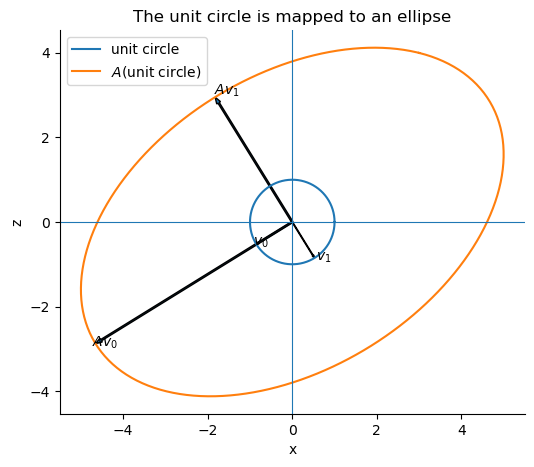

In [3]:
theta = np.linspace(0, 2 * np.pi, 500)
circle = np.vstack([np.cos(theta), np.sin(theta)])
image = A @ circle

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(circle[0], circle[1], label="unit circle")
ax.plot(image[0], image[1], label="$A$(unit circle)")
+
for i in range(2):
	v = eigvecs[:, i]
	Av = A @ v
	ax.arrow(0, 0, v[0], v[1], width=0.015, length_includes_head=True)
	ax.arrow(0, 0, Av[0], Av[1], width=0.035, length_includes_head=True)
	ax.text(1.08 * v[0], 1.08 * v[1], f"$v_{i}$")
	ax.text(1.02 * Av[0], 1.02 * Av[1], f"$Av_{i}$")

ax.set_aspect("equal", adjustable="box")
ax.axhline(0, lw=0.8)
ax.axvline(0, lw=0.8)
ax.set_xlabel("x")
ax.set_ylabel("z")
ax.set_title("The unit circle is mapped to an ellipse")
ax.legend()
plt.show()


The positive eigenvalue stretches the vector in the same direction. The negative eigenvalue stretches by its absolute value and reverses the direction along that eigenspace. Hence the image ellipse has semi-axis lengths $|1+2\sqrt{5}|$ and $|1-2\sqrt{5}|$.


### Exercise 1.3 — compare $\|A\|_2$ and $\|A\|_F$


In [4]:
norm_2 = np.linalg.norm(A, 2)
norm_F = np.linalg.norm(A, "fro")

print(f"||A||_2 = {norm_2:.12f}")
print(f"||A||_F = {norm_F:.12f}")
print(f"max |eigenvalue| = {np.max(np.abs(eigvals)):.12f}")
print(f"sqrt(sum eigenvalue^2) = {np.sqrt(np.sum(eigvals**2)):.12f}")


||A||_2 = 5.472135955000
||A||_F = 6.480740698408
max |eigenvalue| = 5.472135955000
sqrt(sum eigenvalue^2) = 6.480740698408


For a real symmetric matrix, the spectral norm is the largest absolute eigenvalue. Here

$$
\|A\|_2 = 1+2\sqrt{5}\approx 5.4721.
$$

The Frobenius norm is

$$
\|A\|_F = \sqrt{3^2 + 4^2 + 4^2 + (-1)^2} = \sqrt{42}\approx 6.4807.
$$

The Frobenius norm is larger because it aggregates all squared entries, equivalently all squared singular values.


### Exercise 1.4 — compute $\exp(A)$


In [5]:
expA_numeric = expm(A)

I2 = np.eye(2)
B_shift = A - I2
expA_closed = np.e * (
	np.cosh(2 * np.sqrt(5)) * I2
	+ (np.sinh(2 * np.sqrt(5)) / (2 * np.sqrt(5))) * B_shift
)

print_matrix("expm(A), scipy", expA_numeric)
print()
print_matrix("expm(A), closed form", expA_closed)
print("\nAgreement:", np.allclose(expA_numeric, expA_closed))


expm(A), scipy =
[[172.203801 106.408611]
 [106.408611  65.795189]]

expm(A), closed form =
[[172.203801 106.408611]
 [106.408611  65.795189]]

Agreement: True


The closed form works because $A=I+B$ and $B^2=20I$. Powers of $B$ therefore collapse into even and odd terms, giving hyperbolic cosine and sine.


## 2. Eigenvalues of sums of symmetric matrices

For

$$
Q = \begin{pmatrix}\cos\varphi & -\sin\varphi\\ \sin\varphi & \cos\varphi\end{pmatrix},
\quad
A = Q\begin{pmatrix}3 & 0\\0 & -1\end{pmatrix}Q^{-1},
\quad
B = \begin{pmatrix}2 & 0\\0 & 0\end{pmatrix},
$$

we have $Q^{-1}=Q^T$ because $Q$ is orthogonal. Therefore $A$ is symmetric and has eigenvalues $3$ and $-1$ for every $\varphi$. The matrix $B$ has eigenvalues $2$ and $0$.


### Exercise 2.1 — construct the matrices


In [6]:
def rot(phi):
	return np.array([[np.cos(phi), -np.sin(phi)],
	                 [np.sin(phi),  np.cos(phi)]], dtype=float)


def A_of_phi(phi):
	Q = rot(phi)
	D = np.diag([3.0, -1.0])
	return Q @ D @ Q.T

B_sum = np.array([[2, 0],
                  [0, 0]], dtype=float)

phi = np.pi / 4
A_sum = A_of_phi(phi)
print_matrix("A(pi/4)", A_sum)
print_matrix("B", B_sum)
print_matrix("A(pi/4) + B", A_sum + B_sum)


A(pi/4) =
[[1. 2.]
 [2. 1.]]
B =
[[2. 0.]
 [0. 0.]]
A(pi/4) + B =
[[3. 2.]
 [2. 1.]]


For $\varphi=\pi/4$ this gives

$$
A = \begin{pmatrix}1 & 2\\2 & 1\end{pmatrix},
\qquad
A+B = \begin{pmatrix}3 & 2\\2 & 1\end{pmatrix}.
$$


### Exercise 2.2 — eigenvalues for $\varphi=45^\circ$


In [7]:
alpha, _ = sorted_eigh(A_sum)
beta, _ = sorted_eigh(B_sum)
gamma, _ = sorted_eigh(A_sum + B_sum)

print("lambda(A):", alpha)
print("lambda(B):", beta)
print("lambda(A+B):", gamma)
print("Expected exact gamma:", [2 + np.sqrt(5), 2 - np.sqrt(5)])


lambda(A): [ 3. -1.]
lambda(B): [2. 0.]
lambda(A+B): [ 4.236068 -0.236068]
Expected exact gamma: [np.float64(4.23606797749979), np.float64(-0.2360679774997898)]


Thus

$$
\gamma_1 = 2+\sqrt{5}\approx 4.2361,
\qquad
\gamma_2 = 2-\sqrt{5}\approx -0.2361.
$$


### Exercise 2.3 — compare with eigenvalue bounds

A useful consequence of Weyl's inequalities is

$$
\lambda_i(A) + \lambda_{\min}(B)
\leq
\lambda_i(A+B)
\leq
\lambda_i(A) + \lambda_{\max}(B).
$$

Here $\lambda_{\min}(B)=0$ and $\lambda_{\max}(B)=2$.


In [8]:
lower = alpha + beta[-1]
upper = alpha + beta[0]

print("Bounds using A as the reference matrix:")
for i in range(2):
	print(f"i={i+1}:  {lower[i]: .6f} <= gamma_{i+1} = {gamma[i]: .6f} <= {upper[i]: .6f}")

lower_swapped = beta + alpha[-1]
upper_swapped = beta + alpha[0]

print("\nBounds after swapping A and B:")
for i in range(2):
	print(f"i={i+1}:  {lower_swapped[i]: .6f} <= gamma_{i+1} = {gamma[i]: .6f} <= {upper_swapped[i]: .6f}")


Bounds using A as the reference matrix:
i=1:   3.000000 <= gamma_1 =  4.236068 <=  5.000000
i=2:  -1.000000 <= gamma_2 = -0.236068 <=  1.000000

Bounds after swapping A and B:
i=1:   1.000000 <= gamma_1 =  4.236068 <=  5.000000
i=2:  -1.000000 <= gamma_2 = -0.236068 <=  3.000000


The theorem is correct in this example. Using $A$ as the reference matrix gives intervals

$$
\gamma_1 \in [3,5], \qquad \gamma_2 \in [-1,1],
$$

both of length $2$. Swapping $A$ and $B$ gives

$$
\gamma_1 \in [1,5], \qquad \gamma_2 \in [-1,3],
$$

both of length $4$. The swapped version is still valid but less informative here because $A$ has a wider spectral spread than $B$.


### Bonus — tightness of the bound

For general $\varphi$ one can derive

$$
\lambda(A(\varphi)+B)=2\pm\sqrt{5+4\cos(2\varphi)}.
$$

The bounds are not tight at $\varphi=\pi/4$, but they are tight over the family: the endpoints are attained when the eigenvectors of $A$ align with those of $B$.


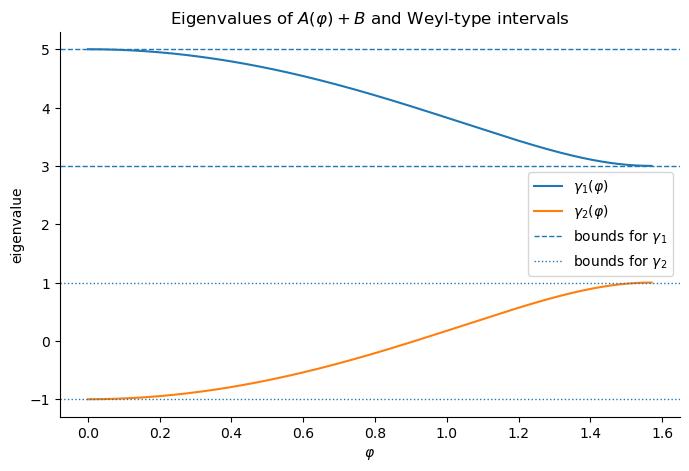

gamma_1 range over scan: [3.000000, 5.000000]
gamma_2 range over scan: [-1.000000, 1.000000]


In [9]:
phis = np.linspace(0, np.pi / 2, 400)
gammas = np.array([sorted_eigh(A_of_phi(phi) + B_sum)[0] for phi in phis])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(phis, gammas[:, 0], label="$\\gamma_1(\\varphi)$")
ax.plot(phis, gammas[:, 1], label="$\\gamma_2(\\varphi)$")
ax.axhline(lower[0], ls="--", lw=1, label="bounds for $\\gamma_1$")
ax.axhline(upper[0], ls="--", lw=1)
ax.axhline(lower[1], ls=":", lw=1, label="bounds for $\\gamma_2$")
ax.axhline(upper[1], ls=":", lw=1)
ax.set_xlabel("$\\varphi$")
ax.set_ylabel("eigenvalue")
ax.set_title("Eigenvalues of $A(\\varphi)+B$ and Weyl-type intervals")
ax.legend()
plt.show()

print(f"gamma_1 range over scan: [{gammas[:, 0].min():.6f}, {gammas[:, 0].max():.6f}]")
print(f"gamma_2 range over scan: [{gammas[:, 1].min():.6f}, {gammas[:, 1].max():.6f}]")


At $\varphi=\pi/4$, the largest deviation from the reference eigenvalues of $A$ is

$$
\max_i |\lambda_i(A+B)-\lambda_i(A)| = \sqrt{5}-1 \approx 1.2361,
$$

while the perturbation bound allows a shift as large as $\|B\|_2=2$. The bound is therefore not tight at this angle, but it is tight for aligned eigenspaces.


## 3. Matrix norms in dimension 3

Consider

$$
A = \begin{pmatrix}
9 & 4 & -4\\
4 & 16 & 0\\
-4 & 0 & 2
\end{pmatrix}.
$$


### Exercise 3.1 — eigensystem and norms


In [10]:
A3 = np.array([[9, 4, -4],
               [4, 16, 0],
               [-4, 0, 2]], dtype=float)

vals3, vecs3 = sorted_eigh(A3)

print("Eigenvalues, descending:")
print(vals3)
print("\nEigenvectors, as columns:")
print(vecs3)
print("\nVerification:", np.allclose(A3 @ vecs3, vecs3 @ np.diag(vals3)))

norm_1 = np.linalg.norm(A3, 1)
norm_2 = np.linalg.norm(A3, 2)
norm_inf = np.linalg.norm(A3, np.inf)
norm_F = np.linalg.norm(A3, "fro")

print("\nNorms:")
print(f"||A||_1     = {norm_1:.6f}")
print(f"||A||_2     = {norm_2:.6f}")
print(f"||A||_inf   = {norm_inf:.6f}")
print(f"||A||_F     = {norm_F:.6f}")


Eigenvalues, descending:
[18.  9. -0.]

Eigenvectors, as columns:
[[ 0.444444 -0.777778 -0.444444]
 [ 0.888889  0.444444  0.111111]
 [-0.111111  0.444444 -0.888889]]

Verification: True

Norms:
||A||_1     = 20.000000
||A||_2     = 18.000000
||A||_inf   = 20.000000
||A||_F     = 20.124612


The exact eigenvalues are

$$
18,
\qquad
9,
\qquad
0.
$$

One valid set of corresponding eigenvectors is

$$
\lambda=18: (-4,-8,1)^T,
\qquad
\lambda=9: (-7,4,4)^T,
\qquad
\lambda=0: (4,-1,8)^T.
$$

The matrix norms are

$$
\|A\|_1 = 20,
\qquad
\|A\|_2 = 18,
\qquad
\|A\|_\infty = 20,
\qquad
\|A\|_F = \sqrt{405}=9\sqrt{5}\approx20.1246.
$$

The equality $\|A\|_1=\|A\|_\infty$ occurs here because the matrix is symmetric and the maximal absolute row/column sum is the second row/column. This is not the same thing as the spectral norm.


## 4. Orthogonal projection and best-fit subspaces

Use the rows of

$$
A = \begin{pmatrix}
9 & 4 & -4\\
4 & 16 & 0\\
-4 & 0 & 2\\
0 & 0 & 1
\end{pmatrix}
$$

as four data points in $\mathbb{R}^3$. We project onto

$$
V = \operatorname{span}\{(2,1,2)^T,(2,-2,-1)^T\}.
$$


### Exercise 4.1 — projection onto the given subspace

The two spanning vectors are orthogonal and both have squared norm $9$. Therefore

$$
P = \frac{v_0v_0^T + v_1v_1^T}{9}.
$$

The general formula $P = B(B^TB)^{-1}B^T$ gives the same result.


In [11]:
A4 = np.array([[9, 4, -4],
               [4, 16, 0],
               [-4, 0, 2],
               [0, 0, 1]], dtype=float)

v0 = np.array([2, 1, 2], dtype=float)
v1 = np.array([2, -2, -1], dtype=float)
V_basis = np.column_stack([v0, v1])

print("v0 dot v1:", np.dot(v0, v1))
print("||v0||^2, ||v1||^2:", np.dot(v0, v0), np.dot(v1, v1))

P_given = projector_from_basis(V_basis)
A4_projected = A4 @ P_given

print()
print_matrix("P_given", P_given)
print()
print_matrix("Projected rows", A4_projected)


v0 dot v1: 0.0
||v0||^2, ||v1||^2: 9.0 9.0

P_given =
[[ 0.888889 -0.222222  0.222222]
 [-0.222222  0.555556  0.444444]
 [ 0.222222  0.444444  0.555556]]

Projected rows =
[[ 6.222222 -1.555556  1.555556]
 [ 0.        8.        8.      ]
 [-3.111111  1.777778  0.222222]
 [ 0.222222  0.444444  0.555556]]


The projected rows are

$$
\begin{pmatrix}
56/9 & -14/9 & 14/9\\
0 & 8 & 8\\
-28/9 & 16/9 & 2/9\\
2/9 & 4/9 & 5/9
\end{pmatrix}.
$$


### Exercise 4.2 — is this the best-fit 2-subspace?

For a subspace projector $P$, the squared reconstruction error is $\|A-AP\|_F^2$. The best rank-2 subspace is spanned by the first two right singular vectors of $A$.


In [12]:
residual_given = np.linalg.norm(A4 - A4 @ P_given, "fro") ** 2

U4, s4, Vt4 = sorted_svd(A4)
best_basis = Vt4[:2].T
P_best = projector_from_basis(best_basis)
residual_best = np.linalg.norm(A4 - A4 @ P_best, "fro") ** 2

print("Singular values:", s4)
print(f"Squared residual, given subspace: {residual_given:.12f}")
print(f"Squared residual, best  subspace: {residual_best:.12f}")
print(f"Smallest singular value squared: {s4[-1]**2:.12f}")


Singular values: [18.000344  9.011074  0.887779]
Squared residual, given subspace: 221.000000000000
Squared residual, best  subspace: 0.788152436169
Smallest singular value squared: 0.788152436169


The given subspace is not a best-fit 2-subspace. Its squared residual is $221$, while the optimal residual is approximately $0.78815$. By the Eckart-Young theorem, the optimal residual for a rank-2 approximation is the square of the third singular value.


### Exercise 4.3 — describe the best-fit 2-subspace


In [13]:
normal_best = Vt4[-1]
normal_given = np.cross(v0, v1)
normal_given = normal_given / np.linalg.norm(normal_given)

print_matrix("Best basis, columns", best_basis)
print("Normal to best-fit plane:", normal_best)
print("Normal to given plane:   ", normal_given)
print("Angle similarity between normals:", sign_invariant_similarity(normal_best, normal_given))


Best basis, columns =
[[-0.444467  0.775494]
 [-0.888832 -0.444076]
 [ 0.111474 -0.448783]]
Normal to best-fit plane: [-0.448396  0.113022 -0.886661]
Normal to given plane:    [ 0.333333  0.666667 -0.666667]
Angle similarity between normals: 0.5169901634839228


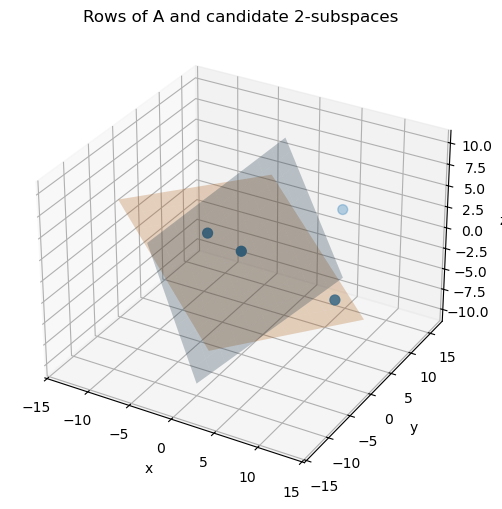

In [14]:
# Optional visualization of the four data points and the two planes.
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(A4[:, 0], A4[:, 1], A4[:, 2], s=50, label="rows of A")

# Creating a small grid in coordinates of each plane.
grid = np.linspace(-10, 10, 11)
c1, c2 = np.meshgrid(grid, grid)

for basis, name, alpha in [(V_basis / 3, "given plane", 0.25), (best_basis, "best-fit plane", 0.25)]:
	pts = c1[..., None] * basis[:, 0] + c2[..., None] * basis[:, 1]
	ax.plot_surface(pts[..., 0], pts[..., 1], pts[..., 2], alpha=alpha)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Rows of A and candidate 2-subspaces")
plt.show()


The best-fit plane is the span of the first two rows of `Vt4`, equivalently the orthogonal complement of the last row of `Vt4`. The exact symbolic form is not illuminating here; the numerical basis is the correct practical description.


## 5. Why the greedy SVD algorithm works

Assume the SVD is

$$
A = \sum_{i < k} \sigma_i |u_i\rangle \langle v_i|,
\qquad
\sigma_0 \geq \sigma_1 \geq \cdots \geq 0.
$$


### Exercise 5.1 — proof sketch

Because the right singular vectors are orthonormal,

$$
\langle v_i|v_0\rangle = \delta_{i0}.
$$

Therefore

$$
\begin{aligned}
A(I-|v_0\rangle\langle v_0|)
&= \sum_{i<k}\sigma_i |u_i\rangle\langle v_i|(I-|v_0\rangle\langle v_0|)\\
&= \sum_{i<k}\sigma_i |u_i\rangle\left(\langle v_i| - \langle v_i|v_0\rangle\langle v_0|\right)\\
&= \sum_{i<k}\sigma_i |u_i\rangle\left(\langle v_i| - \delta_{i0}\langle v_0|\right)\\
&= \sum_{1\leq i<k}\sigma_i |u_i\rangle\langle v_i|.
\end{aligned}
$$

The largest remaining singular value is $\sigma_1$, so the first right singular vector of the deflated matrix is $v_1$, provided there is no degeneracy that makes the singular vector non-unique.


### Exercise 5.2 — implement the first right singular vector


In [15]:
def first_right_singular_vector(A):
	U, s, Vt = np.linalg.svd(np.asarray(A, dtype=float), full_matrices=False)
	return Vt[0]


### Exercise 5.3 — extract the second and third right singular vectors by deflation


In [16]:
M = rng.normal(size=(8, 4))
I4 = np.eye(4)

v0_greedy = first_right_singular_vector(M)
M1 = M @ (I4 - np.outer(v0_greedy, v0_greedy))

v1_greedy = first_right_singular_vector(M1)
M2 = M1 @ (I4 - np.outer(v1_greedy, v1_greedy))

v2_greedy = first_right_singular_vector(M2)

print("Greedy right singular vectors:")
print_matrix("v0", v0_greedy)
print_matrix("v1", v1_greedy)
print_matrix("v2", v2_greedy)


Greedy right singular vectors:
v0 =
[ 0.212686 -0.298861  0.609388 -0.702918]
v1 =
[0.696334 0.683714 0.198091 0.091732]
v2 =
[-0.371882  0.565634 -0.343621 -0.650913]


The multiplication is on the right because we are removing directions in the input space, i.e. the space of right singular vectors.


### Exercise 5.4 — compare with NumPy's SVD


In [17]:
U, s, Vt = np.linalg.svd(M, full_matrices=False)

print("Singular values:", s)
print()
for j, v_greedy in enumerate([v0_greedy, v1_greedy, v2_greedy]):
	similarity = sign_invariant_similarity(v_greedy, Vt[j])
	print(f"v{j}: |cos(angle with NumPy Vt[{j}])| = {similarity:.12f}")


Singular values: [3.690198 2.004741 1.807338 1.113932]

v0: |cos(angle with NumPy Vt[0])| = 1.000000000000
v1: |cos(angle with NumPy Vt[1])| = 1.000000000000
v2: |cos(angle with NumPy Vt[2])| = 1.000000000000


All similarities should be numerically equal to $1$, up to floating-point error. A value of $-1$ before taking the absolute value would also be correct, because singular vectors are defined only up to sign.


### Exercise 5.5 — a reusable greedy routine


In [18]:
def greedy_right_singular_vectors(A, k):
	"""Returning the first k right singular vectors using repeated right deflation."""
	A_work = np.asarray(A, dtype=float).copy()
	d = A_work.shape[1]
	I = np.eye(d)
	vectors = []

	for _ in range(k):
		v = first_right_singular_vector(A_work)
		vectors.append(v)
		A_work = A_work @ (I - np.outer(v, v))

	return np.array(vectors)

V_greedy = greedy_right_singular_vectors(M, k=3)

print("Pairwise comparison with NumPy Vt:")
for j in range(3):
	print(f"v{j}: {sign_invariant_similarity(V_greedy[j], Vt[j]):.12f}")

print("\nOrthogonality check for greedy vectors:")
print_matrix("V_greedy @ V_greedy.T", V_greedy @ V_greedy.T)


Pairwise comparison with NumPy Vt:
v0: 1.000000000000
v1: 1.000000000000
v2: 1.000000000000

Orthogonality check for greedy vectors:
V_greedy @ V_greedy.T =
[[ 1. -0.  0.]
 [-0.  1.  0.]
 [ 0.  0.  1.]]


The greedy algorithm reproduces the SVD directions because each deflation step removes the current right singular direction while preserving the remaining singular-vector expansion. In real applications, one must handle degeneracies and numerical roundoff carefully; the random matrix here has distinct singular values, so the comparison is clean.
